# Identification des utilisateurs de Copilote — Solution

Ce notebook suit l'ordre du notebook `BE_CS1_indications.ipynb`. Le chargement, la première analyse, la construction des caractéristiques et leurs statistiques descriptives sont implémentés. La modélisation et les étapes suivantes seront complétées progressivement.

## 1. Prendre connaissance du problème et des données

L'objectif est de prédire l'utilisateur à partir d'une session d'utilisation de Copilote. Il s'agit d'une classification supervisée multiclasse.

Chaque ligne du CSV représente une session. Dans `train.csv`, les deux premiers champs sont l'identifiant utilisateur (`utilisateur`) et le navigateur (`navigateur`). Dans `test.csv`, l'utilisateur est inconnu : le premier champ est le navigateur. Les champs suivants sont une suite d'actions et de marqueurs temporels (`t5`, `t10`, etc.). Les sessions ont des longueurs différentes.


## 2. Chargement des données brutes en mémoire

On reprend la méthode du professeur : `readlines()` permet de déterminer le nombre maximal de champs, `seek(0)` ramène au début du fichier, puis `pd.read_csv()` construit un DataFrame complet.

Les colonnes des éléments sont numérotées à partir de `0`. Leur numéro indique une position dans la session, pas un type d'action. Pandas complète les lignes courtes par des valeurs manquantes (`NaN`). Le nom `max_actions` utilisé dans les indications compte en réalité tous les champs, y compris les métadonnées : on le nomme ici `max_colonnes`.


In [ ]:
from pathlib import Path

import pandas as pd
from IPython.display import display


def read_ds(ds_name: str):
    """Charger un CSV de sessions de longueurs variables, comme dans les indications."""
    with open(Path("Data") / f"{ds_name}.csv", encoding="utf-8") as fichier:
        max_colonnes = max(len(ligne.rstrip("\r\n").split(",")) for ligne in fichier.readlines())
        fichier.seek(0)
        noms = ["utilisateur", "navigateur"] if ds_name == "train" else ["navigateur"]
        noms.extend(range(max_colonnes - len(noms)))
        return pd.read_csv(fichier, names=noms, dtype=str)


features_train = read_ds("train")
features_test = read_ds("test")

print("Dimensions (lignes, colonnes) :")
print("Train :", features_train.shape)
print("Test :", features_test.shape)


### Affichage des 20 premières lignes

L'aperçu utilise le DataFrame complet : il conserve donc toutes les colonnes définies à partir de la session la plus longue de l'ensemble d'entraînement. Aucune colonne ni aucun texte de cellule n'est tronqué. Faites défiler horizontalement pour parcourir le tableau.


In [ ]:
with pd.option_context(
    "display.max_rows", 20,
    "display.max_columns", None,
    "display.max_colwidth", None,
):
    display(features_train.head(20))


## 3. Première analyse des données

Les nombreuses valeurs manquantes en fin de session proviennent du remplissage nécessaire à la construction du tableau rectangulaire. Il ne faut donc pas supprimer une session simplement parce qu'elle contient ces valeurs.

### 3.1. Navigateurs présents


In [ ]:
print("Navigateurs du jeu d'entraînement :")
print(features_train["navigateur"].unique())
print("Navigateurs du jeu de test :")
print(features_test["navigateur"].unique())

navigateurs = pd.concat([
    features_train["navigateur"].value_counts().rename("entraînement"),
    features_test["navigateur"].value_counts().rename("test"),
], axis=1).fillna(0).astype(int)
display(navigateurs)


Navigateurs du jeu d'entraînement :
<StringArray>
['Firefox', 'Google Chrome', 'Microsoft Edge', 'Opera']
Length: 4, dtype: str
Navigateurs du jeu de test :
<StringArray>
['Microsoft Edge', 'Firefox', 'Google Chrome', 'Opera']
Length: 4, dtype: str


,entraînement,test
navigateur,,
Firefox,1466,147
Google Chrome,1339,133
Microsoft Edge,451,42
Opera,23,2


### 3.2. Navigateurs par utilisateur

Comme demandé dans les indications, on compte les sessions de chaque utilisateur pour chaque navigateur. Le tableau complet est conservé dans `navigateurs_par_utilisateur` ; on en affiche les 20 premières lignes.


In [ ]:
def browsers_per_player(df):
    return pd.crosstab(df["utilisateur"], df["navigateur"])


navigateurs_par_utilisateur = browsers_per_player(features_train)
display(navigateurs_par_utilisateur.head(20))


navigateur,Firefox,Google Chrome,Microsoft Edge,Opera
utilisateur,,,,
aho,0,10,0,0
ajo,13,0,0,0
akx,0,14,0,0
ald,0,15,0,0
ats,12,0,0,0
avt,15,0,0,0
azn,0,4,0,0
azo,0,10,0,0
azx,0,10,0,0


**Interprétation à compléter :** certains utilisateurs emploient-ils plusieurs navigateurs ? Le navigateur semble-t-il suffisant pour identifier une personne ?

### 3.3. Longueurs des sessions

On compte les éléments non manquants après les métadonnées. Ce nombre inclut les actions et les marqueurs temporels : il ne mesure donc ni le nombre exact d'actions ni la durée d'une session.


In [ ]:
longueurs_train = features_train.iloc[:, 2:].count(axis=1)
longueurs_test = features_test.iloc[:, 1:].count(axis=1)

display(pd.DataFrame({
    "entraînement": longueurs_train.describe(),
    "test": longueurs_test.describe(),
}))

# Part des cases vides dans les colonnes d'éléments, sans inclure les métadonnées.
for nom, df, longueurs, decalage in [
    ("Entraînement", features_train, longueurs_train, 2),
    ("Test", features_test, longueurs_test, 1),
]:
    nombre_cases = len(df) * (df.shape[1] - decalage)
    proportion_vide = 1 - longueurs.sum() / nombre_cases
    print(f"{nom} : {proportion_vide:.2%} de cases vides dans les colonnes d'éléments")


,entraînement,test
count,3279.000000,324.000000
mean,850.238792,818.447531
std,1212.323701,1003.002175
min,2.000000,13.000000
25%,192.000000,200.750000
50%,423.000000,450.000000
75%,1019.000000,1005.250000
max,14468.000000,7725.000000


Entraînement : 94.12% de cases vides dans les colonnes d'éléments
Test : 89.41% de cases vides dans les colonnes d'éléments


### Les sessions très longues sont-elles exceptionnelles ?

L'histogramme complète les statistiques précédentes. Les intervalles sont espacés logarithmiquement : on distingue les sessions courtes tout en conservant les plus longues. Chaque barre compte des sessions ; la longueur inclut actions et marqueurs temporels. Une longueur extrême n'implique pas une erreur.


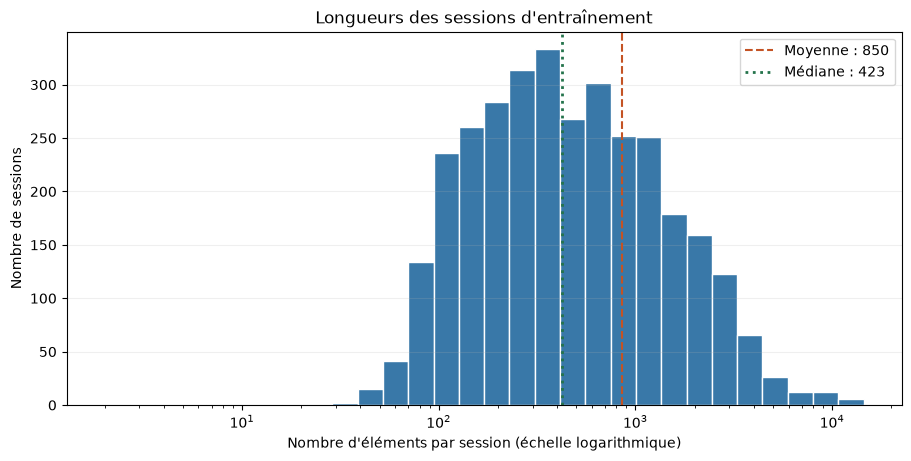

Sessions sans élément : 0
95 % des sessions ont au plus 2900 éléments (quantile estimé).
Maximum observé : 14468 éléments.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

DOSSIER_FIGURES = Path("figures")
DOSSIER_FIGURES.mkdir(exist_ok=True)

# Les longueurs nulles, incompatibles avec l'échelle logarithmique, sont signalées.
longueurs_positives = longueurs_train[longueurs_train > 0]
bornes = np.geomspace(longueurs_positives.min(), longueurs_positives.max() + 1, 31)
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.hist(longueurs_positives, bins=bornes, color="#3978a8", edgecolor="white")
ax.set_xscale("log")
ax.axvline(longueurs_train.mean(), color="#c45324", linestyle="--",
           label=f"Moyenne : {longueurs_train.mean():.0f}")
ax.axvline(longueurs_train.median(), color="#24734b", linestyle=":", linewidth=2,
           label=f"Médiane : {longueurs_train.median():.0f}")
ax.set(title="Longueurs des sessions d'entraînement",
       xlabel="Nombre d'éléments par session (échelle logarithmique)", ylabel="Nombre de sessions")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.savefig(DOSSIER_FIGURES / "01_longueurs_sessions.png", dpi=180)
plt.show()

print(f"Sessions sans élément : {(longueurs_train == 0).sum()}")
print(f"95 % des sessions ont au plus {longueurs_train.quantile(0.95):.0f} éléments (quantile estimé).")
print(f"Maximum observé : {longueurs_train.max()} éléments.")


**Constat sur les données :** la moyenne est d'environ **850 éléments**, contre une médiane de **423**. Le 95e percentile est d'environ **2 900**, alors que le maximum atteint **14 468**. Les sessions les plus longues sont donc peu représentatives de la majorité, mais imposent la largeur du tableau brut.

**Lecture :** comparer la moyenne à la médiane et le 95e percentile au maximum. Une moyenne supérieure à la médiane et une distribution étendue vers les grandes longueurs montrent l'influence des sessions longues. Le tableau brut réserve la même largeur à toutes les sessions, ce qui explique le remplissage massif ; ces valeurs vides ne sont pas, à elles seules, des données perdues.


### 3.4. Distribution de la variable dépendante Y

La variable à prédire est `utilisateur`. On examine le nombre de classes et le nombre de sessions disponibles pour chaque utilisateur.


In [ ]:
def get_Y_stats(df):
    effectifs = df["utilisateur"].value_counts().rename("nombre_sessions")
    stats = effectifs.to_frame()
    stats["proportion"] = effectifs / len(df)
    return stats


stats_Y = get_Y_stats(features_train)
print(f"Nombre d'utilisateurs distincts : {len(stats_Y)}")
display(stats_Y["nombre_sessions"].describe().to_frame())
display(stats_Y.head(20))


Nombre d'utilisateurs distincts : 247


,nombre_sessions
count,247.000000
mean,13.275304
std,8.862380
min,4.000000
25%,7.000000
50%,12.000000
75%,16.000000
max,75.000000


,nombre_sessions,proportion
utilisateur,,
skm,75,0.022873
slq,71,0.021653
cjr,46,0.014029
flj,42,0.012809
hjs,37,0.011284
vfo,35,0.010674
shh,34,0.010369
nqg,34,0.010369
fwf,33,0.010064


### Le déséquilibre concerne-t-il seulement quelques utilisateurs ?

On représente tous les utilisateurs, classés selon leur nombre de sessions. Le rang permet une lecture globale sans afficher 247 identifiants. La part des dix premiers utilisateurs mesure la concentration des sessions.


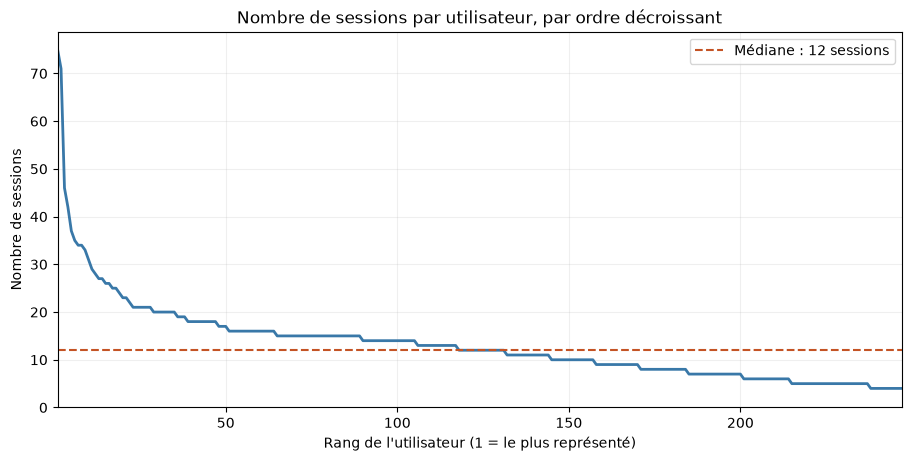

Les 10 utilisateurs les plus représentés regroupent 13.36% des sessions.
Avec autant de sessions par utilisateur, cette part serait de 4.05%.
Rapport entre le plus grand et le plus petit effectif : 18.75.


In [ ]:
effectifs_tries = stats_Y["nombre_sessions"].sort_values(ascending=False)
rangs = np.arange(1, len(effectifs_tries) + 1)
part_top10 = effectifs_tries.head(10).sum() / len(features_train)
part_top10_uniforme = min(10, len(effectifs_tries)) / len(effectifs_tries)

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.plot(rangs, effectifs_tries.to_numpy(), color="#3978a8", linewidth=2)
ax.axhline(effectifs_tries.median(), color="#c45324", linestyle="--",
           label=f"Médiane : {effectifs_tries.median():.0f} sessions")
ax.set(title="Nombre de sessions par utilisateur, par ordre décroissant",
       xlabel="Rang de l'utilisateur (1 = le plus représenté)", ylabel="Nombre de sessions",
       xlim=(1, len(effectifs_tries)), ylim=(0, effectifs_tries.max() * 1.05))
ax.legend()
ax.grid(alpha=0.2)
fig.savefig(DOSSIER_FIGURES / "02_effectifs_utilisateurs.png", dpi=180)
plt.show()

print(f"Les 10 utilisateurs les plus représentés regroupent {part_top10:.2%} des sessions.")
print(f"Avec autant de sessions par utilisateur, cette part serait de {part_top10_uniforme:.2%}.")
print(f"Rapport entre le plus grand et le plus petit effectif : {effectifs_tries.max() / effectifs_tries.min():.2f}.")


**Constat sur les données :** les dix utilisateurs les plus représentés regroupent **13,36 %** des sessions, contre **4,05 %** avec une répartition uniforme. La médiane est de **12 sessions par utilisateur**, et le rapport entre les effectifs extrêmes vaut **18,75** (75 contre 4). La courbe montre quelques utilisateurs nettement plus représentés, puis une diminution plus progressive des effectifs.

**Lecture :** la forme de la courbe révèle si quelques utilisateurs se distinguent fortement ou si les effectifs diminuent progressivement. Comparer la part des dix premiers à la référence uniforme. Les utilisateurs peu représentés auront moins d'exemples disponibles pour l'apprentissage et la validation ; ce constat guidera notre protocole d'évaluation.


### 3.5. L'entraînement et le test se ressemblent-ils ?

Les ensembles ont des tailles différentes : on compare donc des proportions. Le premier panneau compare les navigateurs. Le second représente la distribution cumulée des longueurs : à une longueur donnée, la hauteur indique la proportion des sessions contenant au plus ce nombre d'éléments.

Cette comparaison porte uniquement sur des données observables, sans utiliser les étiquettes du test. Elle ne sert pas à choisir un modèle selon ses performances sur le test.


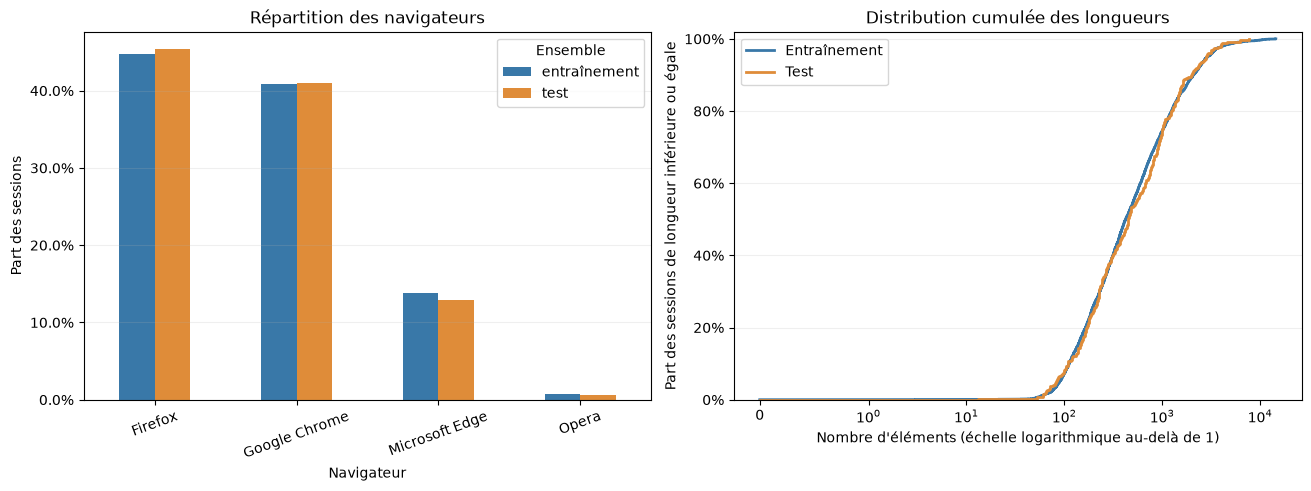

Écart maximal de proportion pour un navigateur : 0.79 points de pourcentage.
Médianes des longueurs : train = 423 ; test = 450.


In [ ]:
proportions_navigateurs = navigateurs.div(navigateurs.sum(axis=0), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
proportions_navigateurs.plot.bar(ax=axes[0], color=["#3978a8", "#df8c39"], rot=20)
axes[0].set(title="Répartition des navigateurs", xlabel="Navigateur", ylabel="Part des sessions")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(title="Ensemble")

for label, longueurs, couleur in [
    ("Entraînement", longueurs_train, "#3978a8"),
    ("Test", longueurs_test, "#df8c39"),
]:
    valeurs, effectifs = np.unique(longueurs.to_numpy(), return_counts=True)
    proportions_cumulees = effectifs.cumsum() / len(longueurs)
    # Un point initial à 0 permet de visualiser le départ de la distribution.
    axes[1].step(np.r_[0, valeurs], np.r_[0, proportions_cumulees],
                 where="post", label=label, color=couleur, linewidth=2)
# symlog conserve les éventuelles sessions de longueur nulle.
axes[1].set_xscale("symlog", linthresh=1)
axes[1].set(title="Distribution cumulée des longueurs", xlabel="Nombre d'éléments (échelle logarithmique au-delà de 1)",
            ylabel="Part des sessions de longueur inférieure ou égale", ylim=(0, 1.02))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend()
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.savefig(DOSSIER_FIGURES / "03_comparaison_train_test.png", dpi=180)
plt.show()

ecart_navigateurs = (proportions_navigateurs.iloc[:, 0] - proportions_navigateurs.iloc[:, 1]).abs().max()
print(f"Écart maximal de proportion pour un navigateur : {100 * ecart_navigateurs:.2f} points de pourcentage.")
print(f"Médianes des longueurs : train = {longueurs_train.median():.0f} ; test = {longueurs_test.median():.0f}.")


**Constat sur les données :** l'écart maximal de part d'un navigateur entre les ensembles est de **0,79 point de pourcentage**. Les médianes sont de **423 éléments** dans l'entraînement et **450** dans le test ; les courbes cumulées sont visuellement proches. Aucun écart majeur n'apparaît sur ces deux aspects, sans garantir pour autant l'absence d'autres différences.

**Lecture :** des barres et des courbes proches indiquent des répartitions voisines sur ces deux aspects. Une différence entre les maxima peut aussi être liée à la taille des échantillons. Cette comparaison descriptive ne prouve ni l'identité des populations ni la capacité du futur modèle à généraliser.


### 3.6. Contrôle de qualité des données brutes

On relit les CSV pour distinguer les champs réellement vides du fichier des `NaN` ajoutés par pandas en fin de session. Les données restent inchangées.

Une **trace identique** désigne ici exactement la même suite ordonnée d'éléments, marqueurs temporels compris, sans le navigateur ni l'identifiant utilisateur. La comparaison ne normalise pas le texte. Le nombre de répétitions compte les copies au-delà de la première occurrence ; les groupes ambigus sont les traces associées à plusieurs utilisateurs dans l'entraînement. Pour le test, cette ambiguïté est inconnue, car les étiquettes sont absentes.


In [ ]:
import csv
from collections import Counter, defaultdict


def controler_fichier(ds_name):
    est_train = ds_name == "train"
    decalage = 2 if est_train else 1
    compteur_traces = Counter()
    utilisateurs_par_trace = defaultdict(set)
    utilisateurs_manquants = 0
    navigateurs_manquants = 0
    sessions_sans_element = 0
    sessions_avec_champ_vide = 0

    with open(Path("Data") / f"{ds_name}.csv", encoding="utf-8", newline="") as fichier:
        for ligne in csv.reader(fichier):
            utilisateur = ligne[0].strip() if est_train and ligne else ""
            navigateur = ligne[decalage - 1].strip() if len(ligne) >= decalage else ""
            trace = tuple(ligne[decalage:])
            utilisateurs_manquants += int(est_train and not utilisateur)
            navigateurs_manquants += int(not navigateur)
            sessions_sans_element += int(not any(element.strip() for element in trace))
            sessions_avec_champ_vide += int(any(not element.strip() for element in trace))
            compteur_traces[trace] += 1
            if est_train and utilisateur:
                utilisateurs_par_trace[trace].add(utilisateur)

    traces_ambigues = [trace for trace, utilisateurs in utilisateurs_par_trace.items() if len(utilisateurs) > 1]
    return pd.Series({
        "Utilisateur manquant (sessions)": utilisateurs_manquants if est_train else pd.NA,
        "Navigateur manquant (sessions)": navigateurs_manquants,
        "Sessions sans élément renseigné": sessions_sans_element,
        "Sessions avec champ d'élément vide dans le CSV": sessions_avec_champ_vide,
        "Traces distinctes répétées (groupes)": sum(n > 1 for n in compteur_traces.values()),
        "Répétitions au-delà de la première occurrence (sessions)": sum(n - 1 for n in compteur_traces.values()),
        "Traces associées à plusieurs utilisateurs (groupes)": len(traces_ambigues) if est_train else pd.NA,
        "Sessions appartenant à ces groupes ambigus": sum(compteur_traces[t] for t in traces_ambigues) if est_train else pd.NA,
    }, dtype="Int64")


controle_qualite = pd.DataFrame({
    "entraînement": controler_fichier("train"),
    "test": controler_fichier("test"),
})
display(controle_qualite)


,entraînement,test
Utilisateur manquant (sessions),0,<NA>
Navigateur manquant (sessions),0,0
Sessions sans élément renseigné,0,0
Sessions avec champ d'élément vide dans le CSV,0,0
Traces distinctes répétées (groupes),0,0
Répétitions au-delà de la première occurrence (sessions),0,0
Traces associées à plusieurs utilisateurs (groupes),0,<NA>
Sessions appartenant à ces groupes ambigus,0,<NA>


**Constat sur les données :** aucun utilisateur d'entraînement ni navigateur n'est manquant ; aucune session n'est vide et aucun champ d'élément du CSV n'est vide. Aucune trace exactement répétée n'est détectée **à l'intérieur de chacun des deux ensembles**, selon la définition retenue. Il n'y a donc aucun groupe ambigu détecté dans l'entraînement. Ce contrôle n'exclut pas des sessions presque identiques ou des recouvrements entre train et test, qui ne sont pas recherchés ici.

**Lecture :** `<NA>` signifie « non applicable ou non observable », et non zéro. Une répétition peut être légitime, mais des traces identiques présentes des deux côtés d'une séparation entraînement/validation peuvent rendre l'évaluation trop optimiste. Des traces identiques avec des utilisateurs différents signalent une ambiguïté dans les éléments enregistrés ; le navigateur peut éventuellement apporter une information supplémentaire. Aucune ligne n'est supprimée à cette étape.


## 4. Construction de caractéristiques

Nous transformons chaque session en une ligne de caractéristiques de largeur fixe, indépendante de sa longueur. `features_train` et `features_test` restent les données brutes ; `caracteristiques_train` et `caracteristiques_test` contiendront les variables construites. La cible est conservée séparément.

### 4.1. Traitements préliminaires

Le contrôle précédent ne justifie aucune suppression de session. On retire uniquement les valeurs manquantes de remplissage lors du parcours des éléments, sans modifier les DataFrames bruts. Les sessions très longues sont conservées : nous utilisons des proportions et des transformations `log1p` pour limiter l'influence de leur taille.

On reconnaît un marqueur temporel seulement si l'élément entier respecte `t` suivi de chiffres. Le plus grand `tXX` mesure un **horizon temporel enregistré**, pas nécessairement la durée réelle de connexion. Les répétitions de marqueurs ne prolongent pas cet horizon. Une baisse des valeurs temporelles est signalée ; dans ce cas, le débit calculé à partir de l'horizon reste inconnu.


In [ ]:
import re
from collections import Counter

pattern_temps = re.compile(r"t(\d+)")
pattern_ecran = re.compile(r"\((.*?)\)")
pattern_configuration = re.compile(r"<(.*?)>")
pattern_chaine = re.compile(r"\$(.*?)\$")


def extraire_sequences(df):
    colonnes_elements = [col for col in df.columns if isinstance(col, int)]
    return [
        [valeur for valeur in ligne if isinstance(valeur, str)]
        for ligne in df[colonnes_elements].itertuples(index=False, name=None)
    ]


sequences_train = extraire_sequences(features_train)
sequences_test = extraire_sequences(features_test)


def auditer_temps(sequences):
    bilan = Counter()
    for sequence in sequences:
        temps = [int(m.group(1)) for element in sequence
                 if (m := pattern_temps.fullmatch(element))]
        differences = np.diff(temps)
        bilan["Sessions sans action"] += int(len(temps) == len(sequence))
        bilan["Sessions sans marqueur temporel"] += int(not temps)
        bilan["Sessions avec marqueur temporel répété"] += int(len(temps) != len(set(temps)))
        bilan["Sessions avec retour temporel en arrière"] += int(np.any(differences < 0))
        bilan["Sessions avec saut temporel supérieur à 5 s"] += int(np.any(differences > 5))
    return pd.Series(bilan)


diagnostic_temps = pd.DataFrame({
    "entraînement": auditer_temps(sequences_train),
    "test": auditer_temps(sequences_test),
})
display(diagnostic_temps)


,entraînement,test
Sessions sans action,1,0
Sessions sans marqueur temporel,0,0
Sessions avec marqueur temporel répété,2158,224
Sessions avec retour temporel en arrière,0,0
Sessions avec saut temporel supérieur à 5 s,17,1


**Constats et décision de traitement :** 2 158 sessions d'entraînement et 224 sessions de test contiennent des marqueurs répétés. Aucun retour temporel en arrière n'est observé ; 17 sessions d'entraînement et une de test présentent au moins un saut supérieur à 5 secondes. Une session d'entraînement ne contient aucune action. Nous la conservons avec un indicateur `sans_action` et des proportions d'actions à zéro. Les marqueurs répétés restent dans les traces, mais sont dédupliqués pour compter les instants distincts ; l'horizon repose sur la valeur maximale, jamais sur le nombre de marqueurs multiplié par cinq.

### 4.2. Variable de classe

Comme dans les indications, `pd.Categorical` fournit des codes numériques. Ces codes sont des identifiants de classes, pas des nombres à ordonner ou à introduire comme caractéristiques. On conserve les étiquettes originales et la correspondance pour décoder les prédictions.


In [ ]:
cible_categorielle = pd.Categorical(features_train["utilisateur"])
y_train = pd.Series(cible_categorielle.codes, index=features_train.index, name="classe")
y_utilisateurs = features_train["utilisateur"].copy()
correspondance_classes = pd.Series(cible_categorielle.categories,
                                  index=range(len(cible_categorielle.categories)), name="utilisateur")
display(correspondance_classes.head(10).rename_axis("code").to_frame())
print(f"{len(correspondance_classes)} classes ; cible séparée des caractéristiques.")


,utilisateur
code,
0,aho
1,ajo
2,akx
3,ald
4,ats
5,avt
6,azn
7,azo
8,azx


247 classes ; cible séparée des caractéristiques.


### 4.3. Obtention des caractéristiques

**Lecture des actions.** On sépare le type d'action des informations entre `(...)`, `<...>` et `$...$`. Comme le professeur, on regroupe les variantes suffixées par `1`, mais on conserve séparément leur proportion, leur sens métier n'étant pas documenté. Les apostrophes typographiques sont uniformisées.

Les écrans, configurations et catégories de fiche ne sont comptés que lorsqu'ils sont explicitement renseignés. Une absence de mention ne prouve pas l'absence d'écran ; on ne propage donc pas automatiquement le dernier écran à toutes les actions suivantes.


In [ ]:
def analyser_action(element):
    libelle = re.split(r"[\(<$]", element, maxsplit=1)[0].strip().replace("’", "'")
    variante_1 = libelle.endswith("1")
    type_action = libelle[:-1].rstrip() if variante_1 else libelle
    contexte = {}
    for nom, motif in [("ecran", pattern_ecran), ("configuration", pattern_configuration),
                       ("chaine", pattern_chaine)]:
        match = motif.search(element)
        contexte[nom] = match.group(1).strip() if match else ""
    return type_action, variante_1, contexte


compteur_actions = Counter(
    analyser_action(element)[0]
    for sequence in sequences_train for element in sequence
    if not pattern_temps.fullmatch(element)
)
actions_observees = pd.Series(compteur_actions, name="occurrences").sort_values(ascending=False)
print(f"{len(actions_observees)} types d'actions après regroupement des variantes.")
with pd.option_context("display.max_rows", None):
    display(actions_observees.rename_axis("type_action").to_frame())


35 types d'actions après regroupement des variantes.


,occurrences
type_action,
Exécution d'un bouton,510645
Saisie dans un champ,265633
Sélection d'un écran,206813
Fermeture d'une dialogue,171026
Affichage d'une dialogue,168928
Lancement d'une action générique,115283
Sélection d'un onglet,109209
Raccourci,82176
Création d'un écran,76930


**Variables retenues.** Les proportions d'actions portent sur des familles fixes et lisibles (boutons, saisie, navigation, dialogues, etc.), complétées par `autres`. Leur somme vaut 1 pour une session contenant des actions. Le choix est une première représentation interprétable ; l'identité de chaque écran ou les séquences détaillées pourront être approfondies ensuite.

| Famille | Variables et justification |
|---|---|
| Volume et diversité | Nombre d'actions, nombre de types distincts, diversité relative et entropie : mesurer la variété d'activité. L'entropie vaut 0 si un seul type d'action est présent. |
| Habitudes d'utilisation | Proportions par famille d'actions et proportion de variantes suffixées par `1` : comparer les sessions indépendamment de leur longueur. |
| Enchaînements | Proportion de types d'actions consécutifs identiques et nombre de paires ordonnées distinctes. Les marqueurs temporels sont ignorés pour cette succession. |
| Contexte métier | Nombre d'écrans/configurations/chaînes distincts, taux de mentions explicites, valeur dominante et sa part parmi les mentions. Les égalités sont départagées par ordre alphabétique. |
| Temps | Horizon temporel, marqueurs distincts, répétitions, retours en arrière et débit approximatif d'actions par minute. Ce débit n'est pas une vitesse de clic mesurée. |
| Cas particuliers | Indicateurs de session sans action ou sans repère temporel. Une diversité relative sans action est définie à 0 ; un débit sans horizon fiable reste manquant. |

Les versions `log1p` des dénombrements et de l'horizon sont calculées sans apprentissage : `log1p(0) = 0`. Les effectifs bruts restent disponibles pour les interprétations.


In [ ]:
# Familles fixées explicitement : aucun vocabulaire n'est appris sur le test.
FAMILLES_ACTIONS = {
    "bouton": {"Exécution d'un bouton"},
    "saisie": {"Saisie dans un champ", "Entrée en saisie dans un formulaire"},
    "navigation": {"Sélection d'un écran", "Retour sur un écran", "Création d'un écran", "Sélection d'un onglet"},
    "dialogue": {"Affichage d'une dialogue", "Fermeture d'une dialogue"},
    "raccourci": {"Raccourci", "Raccourci dans l'édition de table"},
    "filtrage": {"Filtrage / Tri"},
    "chainage": {"Chainage"},
    "double_clic": {"Double-clic"},
    "erreur": {"Affichage d'une erreur", "Erreur système grave"},
    "lancement": {"Lancement d'une action générique", "Lancement d'une action infocentre",
                  "Lancement d'une stat", "Lancement d'un tableau de bord"},
}
action_vers_famille = {action: famille for famille, actions in FAMILLES_ACTIONS.items() for action in actions}


def resumer_contexte(valeurs, nom, nombre_actions):
    compte = Counter(valeurs)
    dominant = sorted(compte, key=lambda valeur: (-compte[valeur], valeur))[0] if compte else "__ABSENT__"
    return {
        f"n_{nom}_distincts": len(compte),
        f"part_actions_avec_{nom}": len(valeurs) / nombre_actions if nombre_actions else 0.0,
        f"{nom}_dominant": dominant,
        f"part_{nom}_dominant": compte[dominant] / len(valeurs) if valeurs else 0.0,
    }


def caracteriser_session(sequence, navigateur):
    temps, types = [], []
    contextes = {"ecran": [], "configuration": [], "chaine": []}
    variantes_1 = 0
    for element in sequence:
        marqueur = pattern_temps.fullmatch(element)
        if marqueur:
            temps.append(int(marqueur.group(1)))
            continue
        type_action, variante, contexte = analyser_action(element)
        types.append(type_action)
        variantes_1 += int(variante)
        for nom, valeur in contexte.items():
            if valeur:
                contextes[nom].append(valeur)

    n_actions = len(types)
    compte_types = Counter(types)
    probabilites = np.array(list(compte_types.values()), dtype=float) / n_actions if n_actions else np.array([])
    deltas = np.diff(temps)
    retours = int(np.sum(deltas < 0))
    horizon = max(temps) if temps else np.nan
    debit = n_actions * 60 / horizon if temps and horizon > 0 and retours == 0 else np.nan
    resultat = {
        "navigateur": navigateur if pd.notna(navigateur) else "__ABSENT__",
        "n_actions": n_actions,
        "n_types_actions": len(compte_types),
        "diversite_relative": len(compte_types) / n_actions if n_actions else 0.0,
        "entropie_actions": float(-(probabilites * np.log2(probabilites)).sum()),
        "part_variante_1": variantes_1 / n_actions if n_actions else 0.0,
        "part_repetitions_actions": sum(a == b for a, b in zip(types, types[1:])) / (n_actions - 1) if n_actions > 1 else 0.0,
        "n_paires_actions": len(set(zip(types, types[1:]))),
        "n_marqueurs": len(temps),
        "n_marqueurs_distincts": len(set(temps)),
        "part_marqueurs_repetes": 1 - len(set(temps)) / len(temps) if temps else 0.0,
        "n_retours_temps": retours,
        "horizon_temporel_s": horizon,
        "debit_actions_min_proxy": debit,
        "sans_action": int(n_actions == 0),
        "sans_marqueur": int(not temps),
    }
    familles = Counter(action_vers_famille.get(action, "autres") for action in types)
    for famille in [*FAMILLES_ACTIONS, "autres"]:
        resultat[f"part_action_{famille}"] = familles[famille] / n_actions if n_actions else 0.0
    for nom, valeurs in contextes.items():
        resultat.update(resumer_contexte(valeurs, nom, n_actions))
    for nom in ["n_actions", "n_types_actions", "n_paires_actions", "n_marqueurs", "n_marqueurs_distincts",
                "n_ecran_distincts", "n_configuration_distincts", "n_chaine_distincts", "horizon_temporel_s"]:
        resultat[f"log1p_{nom}"] = np.log1p(resultat[nom])
    return resultat


def construire_caracteristiques(df, sequences):
    lignes = [caracteriser_session(sequence, navigateur)
              for sequence, navigateur in zip(sequences, df["navigateur"])]
    return pd.DataFrame(lignes, index=df.index)


caracteristiques_train = construire_caracteristiques(features_train, sequences_train)
caracteristiques_test = construire_caracteristiques(features_test, sequences_test)
print("Caractéristiques train :", caracteristiques_train.shape)
print("Caractéristiques test :", caracteristiques_test.shape)
with pd.option_context("display.max_columns", None):
    display(caracteristiques_train.head())


Caractéristiques train : (3279, 48)
Caractéristiques test : (324, 48)


,navigateur,n_actions,n_types_actions,diversite_relative,entropie_actions,part_variante_1,part_repetitions_actions,n_paires_actions,n_marqueurs,n_marqueurs_distincts,part_marqueurs_repetes,n_retours_temps,horizon_temporel_s,debit_actions_min_proxy,sans_action,sans_marqueur,part_action_bouton,part_action_saisie,part_action_navigation,part_action_dialogue,part_action_raccourci,part_action_filtrage,part_action_chainage,part_action_double_clic,part_action_erreur,part_action_lancement,part_action_autres,n_ecran_distincts,part_actions_avec_ecran,ecran_dominant,part_ecran_dominant,n_configuration_distincts,part_actions_avec_configuration,configuration_dominant,part_configuration_dominant,n_chaine_distincts,part_actions_avec_chaine,chaine_dominant,part_chaine_dominant,log1p_n_actions,log1p_n_types_actions,log1p_n_paires_actions,log1p_n_marqueurs,log1p_n_marqueurs_distincts,log1p_n_ecran_distincts,log1p_n_configuration_distincts,log1p_n_chaine_distincts,log1p_horizon_temporel_s
0,Firefox,2514,19,0.007558,3.111266,0.000398,0.064067,109,614,581,0.053746,0,2905,51.924269,0,0,0.277645,0.078759,0.040971,0.285998,0.000000,0.064041,0.003182,0.034606,0.002387,0.083134,0.129276,7,0.075975,MAINT,0.465969,3,0.002784,ACCUEIL_GMAO,0.428571,2,0.357597,JCP,0.914349,7.830028,2.995732,4.700480,6.421622,6.366470,2.079442,1.386294,1.098612,7.974533
1,Google Chrome,90,11,0.122222,2.335543,0.266667,0.359551,29,46,46,0.000000,0,230,23.478261,0,0,0.366667,0.377778,0.100000,0.044444,0.011111,0.000000,0.033333,0.000000,0.000000,0.055556,0.011111,5,0.088889,infologic.orga.modules.OR_FICHIERTRAVAIL.Insta...,0.375000,2,0.044444,DEF_03/24,0.500000,2,0.477778,DB,0.953488,4.510860,2.484907,3.401197,3.850148,3.850148,1.791759,1.098612,1.098612,5.442418
2,Microsoft Edge,608,21,0.034539,3.699711,0.078947,0.125206,126,158,150,0.050633,0,750,48.640000,0,0,0.200658,0.075658,0.212171,0.120066,0.064145,0.001645,0.052632,0.036184,0.000000,0.057566,0.179276,17,0.154605,DEMTEST,0.202128,7,0.057566,DEF_07/23,0.371429,2,0.085526,MES,0.750000,6.411818,3.091042,4.844187,5.068904,5.017280,2.890372,2.079442,1.098612,6.621406
3,Firefox,886,19,0.021445,3.208865,0.071106,0.129944,92,313,289,0.076677,0,1445,36.788927,0,0,0.314898,0.094808,0.100451,0.094808,0.000000,0.005643,0.025959,0.002257,0.001129,0.143341,0.216704,10,0.281038,MAINT,0.469880,4,0.010158,DEF_03/24,0.444444,1,0.229120,JCP,1.000000,6.787845,2.995732,4.532599,5.749393,5.669881,2.397895,1.609438,0.693147,7.276556
4,Google Chrome,173,14,0.080925,3.077299,0.011561,0.255814,63,60,55,0.083333,0,275,37.745455,0,0,0.346821,0.208092,0.167630,0.115607,0.000000,0.000000,0.023121,0.011561,0.000000,0.040462,0.086705,8,0.121387,MAINT,0.285714,4,0.040462,DEF_03/24,0.285714,2,0.063584,GP,0.727273,5.159055,2.708050,4.158883,4.110874,4.025352,2.197225,1.609438,1.098612,5.620401


**Vérifications de cohérence.** Le schéma et l'ordre des lignes doivent rester identiques entre données brutes et caractéristiques. Les proportions doivent rester entre 0 et 1. Les valeurs manquantes temporelles sont explicites, sans être remplacées arbitrairement par zéro.


In [ ]:
for brut, construit, longueurs in [
    (features_train, caracteristiques_train, longueurs_train),
    (features_test, caracteristiques_test, longueurs_test),
]:
    assert construit.index.equals(brut.index)
    assert len(construit) == len(brut)
    assert "utilisateur" not in construit.columns
    assert np.array_equal(construit["n_actions"] + construit["n_marqueurs"], longueurs)
    proportions = construit.filter(regex=r"^part_|^diversite_relative$")
    assert ((proportions >= 0) & (proportions <= 1)).all().all()
    assert np.allclose(construit.filter(regex=r"^part_action_").sum(axis=1), 1 - construit["sans_action"])
    assert not np.isinf(construit.select_dtypes(include="number").to_numpy()).any()
assert caracteristiques_train.columns.equals(caracteristiques_test.columns)
print("Cohérence vérifiée : lignes, schéma, cible séparée, comptages et proportions.")


Cohérence vérifiée : lignes, schéma, cible séparée, comptages et proportions.


### 4.4. Traitement des chaînes de caractères

Les quatre variables catégorielles (navigateur, écran, configuration et chaîne dominants) seront encodées en **one-hot**. Une catégorie inconnue sera acceptée sans erreur. Les variables numériques utilisent les versions logarithmiques à la place des dénombrements bruts lorsque disponibles ; les autres restent inchangées avant standardisation.

Le préprocesseur ci-dessous est prêt à l'emploi, mais **n'est pas ajusté ici** : médianes d'imputation, moyennes, écarts-types et catégories doivent être appris sur la seule partie d'entraînement après la séparation de la section 6. Il sera intégré à un `Pipeline` avec le modèle pour éviter les fuites vers la validation. Les statistiques de la section 5 portent sur les caractéristiques lisibles, avant encodage.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

colonnes_categorielles = ["navigateur", "ecran_dominant", "configuration_dominant", "chaine_dominant"]
colonnes_numeriques = [
    col for col in caracteristiques_train.select_dtypes(include="number").columns
    if f"log1p_{col}" not in caracteristiques_train.columns
]


def creer_preprocesseur():
    numerique = Pipeline([
        ("imputation", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("standardisation", StandardScaler()),
    ])
    categoriel = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    return ColumnTransformer([
        ("numerique", numerique, colonnes_numeriques),
        ("categoriel", categoriel, colonnes_categorielles),
    ], sparse_threshold=1.0)


preprocesseur = creer_preprocesseur()
print(f"{len(colonnes_numeriques)} variables numériques et {len(colonnes_categorielles)} catégorielles retenues avant one-hot.")
print("Préprocesseur non ajusté : il sera entraîné uniquement dans le futur pipeline de validation.")


35 variables numériques et 4 catégorielles retenues avant one-hot.
Préprocesseur non ajusté : il sera entraîné uniquement dans le futur pipeline de validation.


## 5. Statistiques simples sur les variables

L'analyse porte maintenant sur les caractéristiques construites, principalement dans l'ensemble d'entraînement. Elle complète la première exploration : nous examinons la composition des actions, leur diversité et les contextes, plutôt que de refaire l'étude des longueurs et des navigateurs.

### 5.1. Inspection des caractéristiques

Le tableau suivant décrit les variables numériques : valeurs manquantes, valeurs distinctes, moyenne, dispersion et quantiles. Les valeurs constantes sont identifiées sans être supprimées sur la base du test. Les variables catégorielles sont résumées séparément : leur nombre de valeurs donne une idée de la largeur du futur encodage one-hot.


In [ ]:
variables_numeriques = caracteristiques_train.select_dtypes(include="number")
statistiques_variables = variables_numeriques.describe().T
statistiques_variables.insert(0, "manquants", variables_numeriques.isna().sum())
statistiques_variables.insert(1, "valeurs_distinctes", variables_numeriques.nunique())
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.precision", 3):
    display(statistiques_variables)

variables_constantes = variables_numeriques.columns[variables_numeriques.nunique(dropna=False) <= 1].tolist()
print("Variables numériques constantes dans l'entraînement :", variables_constantes)

resume_categories = pd.DataFrame({
    "valeurs_distinctes": caracteristiques_train[colonnes_categorielles].nunique(),
    "part_absente": caracteristiques_train[colonnes_categorielles].eq("__ABSENT__").mean(),
})
display(resume_categories)


,manquants,valeurs_distinctes,count,mean,std,min,25%,50%,75%,max
n_actions,0,1365,3279.0,6.924e+02,1005.874,0.000,153.000,340.000,818.500,11977.000
n_types_actions,0,30,3279.0,1.700e+01,4.322,0.000,14.000,17.000,20.000,29.000
diversite_relative,0,2492,3279.0,6.545e-02,0.059,0.000,0.023,0.047,0.092,1.000
entropie_actions,0,3278,3279.0,3.207e+00,0.420,-0.000,3.077,3.296,3.460,4.021
part_variante_1,0,2318,3279.0,1.434e-01,0.181,0.000,0.005,0.080,0.205,0.904
part_repetitions_actions,0,2817,3279.0,1.869e-01,0.105,0.000,0.123,0.165,0.226,0.872
n_paires_actions,0,227,3279.0,8.588e+01,44.696,0.000,51.000,79.000,114.000,254.000
n_marqueurs,0,596,3279.0,1.579e+02,212.514,1.000,38.000,82.000,197.500,2491.000
n_marqueurs_distincts,0,578,3279.0,1.503e+02,201.236,1.000,37.000,79.000,189.000,2358.000
part_marqueurs_repetes,0,972,3279.0,4.209e-02,0.038,0.000,0.000,0.047,0.066,0.240


Variables numériques constantes dans l'entraînement : ['n_retours_temps', 'sans_marqueur']


,valeurs_distinctes,part_absente
navigateur,4,0.000000
ecran_dominant,121,0.000305
configuration_dominant,106,0.046661
chaine_dominant,61,0.320525


### Distribution de trois caractéristiques

- **Part des actions de saisie** : indique si la session est surtout consacrée à la saisie.
- **Entropie des types d'actions** : mesure la diversité et l'équilibre des types (en bits). Deux sessions peuvent avoir autant d'actions mais des entropies différentes.
- **Nombre d'écrans distincts explicitement mentionnés** : décrit la variété de contextes observables. L'échelle horizontale est logarithmique au-delà de 1 et conserve la valeur 0.

Ces histogrammes ne sont pas des mesures de performance du futur modèle.


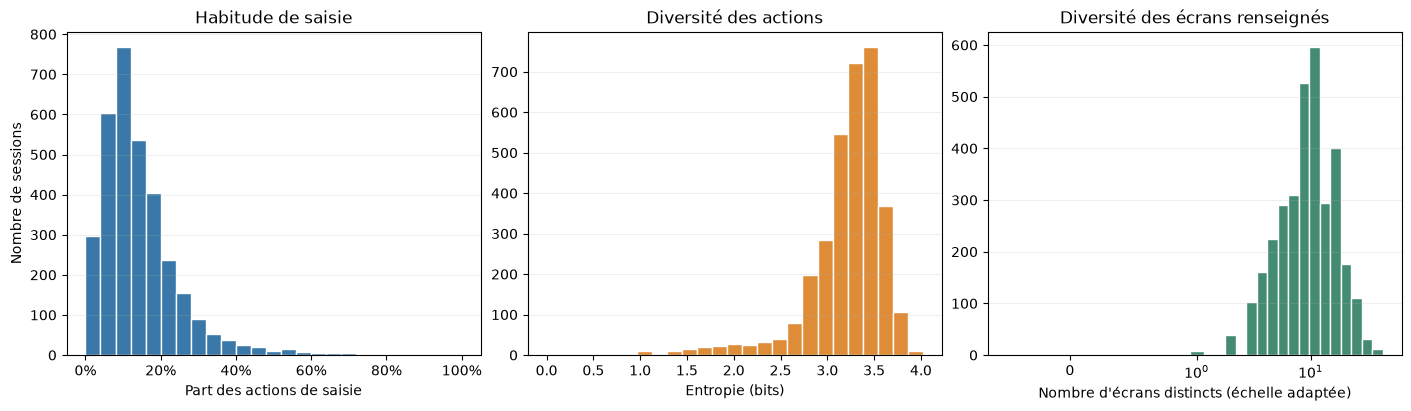

Part médiane d'actions de saisie : 11.8%
Entropie médiane : 3.30 bits
Nombre médian d'écrans distincts renseignés : 9


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
axes[0].hist(caracteristiques_train["part_action_saisie"], bins=np.linspace(0, 1, 26),
             color="#3978a8", edgecolor="white")
axes[0].set(xlabel="Part des actions de saisie", ylabel="Nombre de sessions", title="Habitude de saisie")
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].hist(caracteristiques_train["entropie_actions"], bins=25, color="#df8c39", edgecolor="white")
axes[1].set(xlabel="Entropie (bits)", title="Diversité des actions")
maximum_ecrans = caracteristiques_train["n_ecran_distincts"].max()
bornes_ecrans = np.r_[-0.5, np.geomspace(0.5, maximum_ecrans + 1, 22)]
axes[2].hist(caracteristiques_train["n_ecran_distincts"], bins=bornes_ecrans, color="#438c72", edgecolor="white")
axes[2].set_xscale("symlog", linthresh=1)
axes[2].set(xlabel="Nombre d'écrans distincts (échelle adaptée)", title="Diversité des écrans renseignés")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.savefig(DOSSIER_FIGURES / "04_distributions_caracteristiques.png", dpi=180)
plt.show()

print(f"Part médiane d'actions de saisie : {caracteristiques_train['part_action_saisie'].median():.1%}")
print(f"Entropie médiane : {caracteristiques_train['entropie_actions'].median():.2f} bits")
print(f"Nombre médian d'écrans distincts renseignés : {caracteristiques_train['n_ecran_distincts'].median():.0f}")


**Constats :** la part médiane d'actions de saisie est de **11,8 %**, l'entropie médiane de **3,30 bits** et le nombre médian d'écrans explicitement mentionnés de **9**. La saisie occupe une faible part dans beaucoup de sessions, mais une part élevée dans certaines. L'entropie se concentre autour de 3 à 3,6 bits, avec quelques sessions beaucoup moins diversifiées.

**Interprétation :** une concentration de valeurs faibles peut révéler une activité rare dans une grande partie des sessions ; une forte dispersion peut indiquer des habitudes différentes ou simplement des sessions de tailles différentes. Les écrans non mentionnés ne sont pas observables : une valeur nulle doit être interprétée avec le taux de mentions explicites. Les graphiques par utilisateur ci-dessous examinent si ces différences sont associées à l'identité.


### 5.2. Inspection d'une caractéristique pour une classe particulière

On choisit quatre utilisateurs de manière reproductible parmi ceux ayant au moins dix sessions, à des rangs régulièrement espacés dans la distribution des effectifs. Le choix ne dépend pas des valeurs des caractéristiques.

Chaque boîte présente la médiane et les quartiles ; les points représentent toutes les sessions de l'utilisateur, y compris les valeurs extrêmes. On compare les mêmes caractéristiques que précédemment pour passer de la population entière à des exemples individuels. Le nombre de sessions est indiqué sous chaque utilisateur.


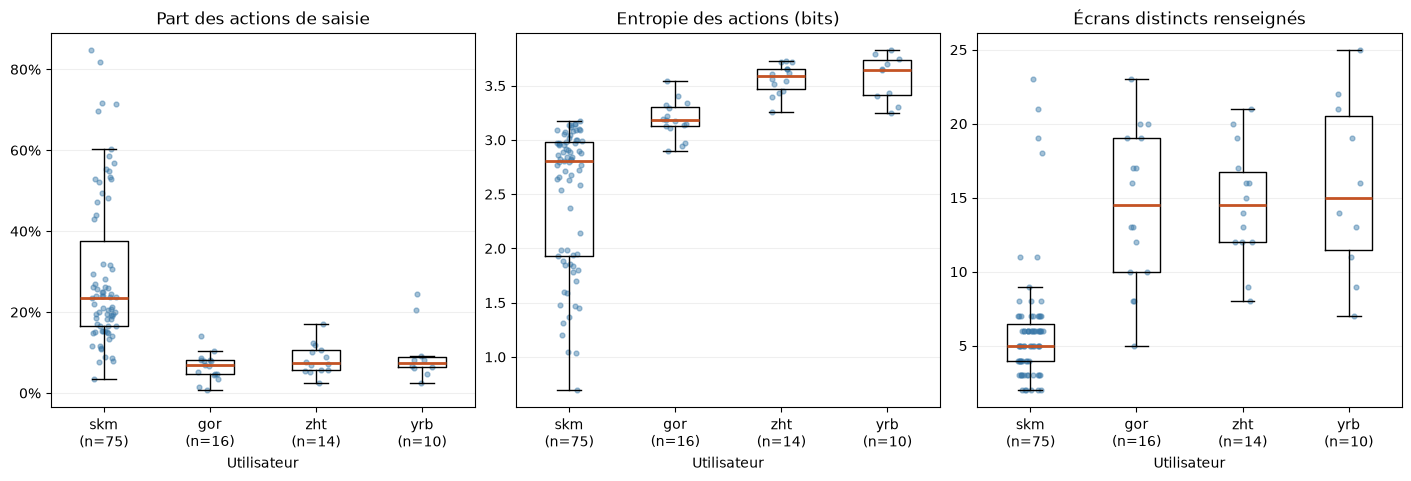

Médianes des caractéristiques pour les utilisateurs sélectionnés :


,part_action_saisie,entropie_actions,n_ecran_distincts
utilisateur,,,
skm,0.234694,2.802401,5.0
gor,0.068821,3.181066,14.5
zht,0.074959,3.586347,14.5
yrb,0.074457,3.645829,15.0


In [ ]:
effectifs_eligibles = stats_Y.loc[stats_Y["nombre_sessions"] >= 10, "nombre_sessions"]
# Les égalités d'effectif sont départagées par l'identifiant pour stabiliser le choix.
effectifs_eligibles = effectifs_eligibles.sort_index().sort_values(ascending=False, kind="stable")
positions = np.linspace(0, len(effectifs_eligibles) - 1, min(4, len(effectifs_eligibles)), dtype=int)
utilisateurs_choisis = effectifs_eligibles.index[positions].tolist()
variables_comparees = ["part_action_saisie", "entropie_actions", "n_ecran_distincts"]
titres = ["Part des actions de saisie", "Entropie des actions (bits)", "Écrans distincts renseignés"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.7), layout="constrained")
rng = np.random.default_rng(42)
for ax, variable, titre in zip(axes, variables_comparees, titres):
    groupes = [caracteristiques_train.loc[y_utilisateurs == utilisateur, variable].dropna().to_numpy()
               for utilisateur in utilisateurs_choisis]
    etiquettes = [f"{utilisateur}\n(n={len(groupe)})" for utilisateur, groupe in zip(utilisateurs_choisis, groupes)]
    ax.boxplot(groupes, tick_labels=etiquettes, showfliers=False,
               medianprops={"color": "#c45324", "linewidth": 2})
    for position, groupe in enumerate(groupes, start=1):
        ax.scatter(position + rng.uniform(-0.12, 0.12, len(groupe)), groupe,
                   s=12, color="#3978a8", alpha=0.45)
    ax.set(title=titre, xlabel="Utilisateur")
    ax.grid(axis="y", alpha=0.2)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
fig.savefig(DOSSIER_FIGURES / "05_caracteristiques_par_utilisateur.png", dpi=180)
plt.show()

comparaison_utilisateurs = caracteristiques_train.loc[
    y_utilisateurs.isin(utilisateurs_choisis), variables_comparees
].assign(utilisateur=y_utilisateurs).groupby("utilisateur").median().reindex(utilisateurs_choisis)
print("Médianes des caractéristiques pour les utilisateurs sélectionnés :")
display(comparaison_utilisateurs)


**Constats pour les quatre utilisateurs retenus :** `skm` présente une part médiane de saisie de **23,5 %**, contre environ **6,9 à 7,5 %** pour `gor`, `zht` et `yrb`. Sa médiane d'écrans distincts est de **5**, contre **14,5 à 15** pour les trois autres. Les distributions se recouvrent néanmoins, et les utilisateurs `zht` et `yrb` sont proches sur ces variables. Ces caractéristiques semblent donc apporter des informations complémentaires, sans suffire à identifier tous les utilisateurs.

**Interprétation :** des médianes différentes et un faible recouvrement suggèrent qu'une variable pourrait aider à distinguer certains utilisateurs. Des boîtes qui se recouvrent montrent qu'elle ne suffit pas à elle seule. Ces quatre exemples ne démontrent pas une séparation des 247 classes : cette hypothèse devra être évaluée sur des sessions de validation non utilisées pour l'entraînement.


### 5.3. Redondance entre caractéristiques numériques

Une matrice de corrélation de **Spearman** compare les rangs des valeurs et aide à repérer les relations monotones, même lorsqu'elles ne sont pas linéaires. On retient un petit ensemble de variables de familles différentes, sans juxtaposer un effectif et son logarithme. Les variables constantes sont exclues de ce graphique.

Les codes des utilisateurs ne sont jamais inclus : leur ordre numérique est arbitraire. Une corrélation ne démontre pas une causalité et ne mesure pas directement le pouvoir prédictif pour la classification.


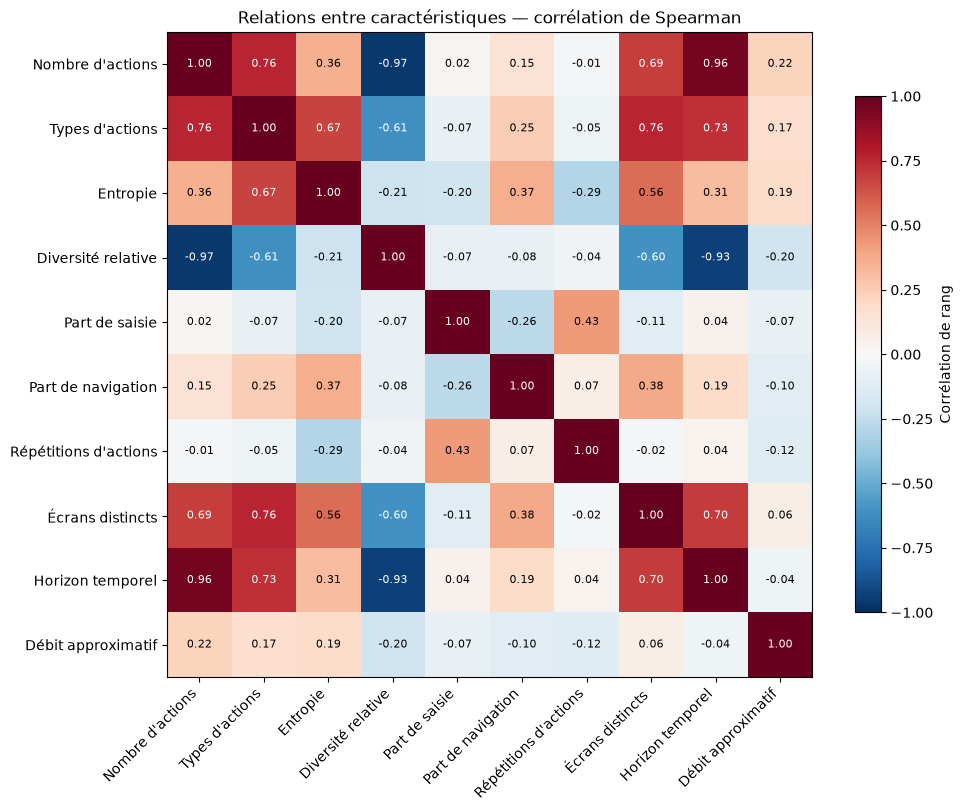

,variable_1,variable_2,rho
2,n_actions,diversite_relative,-0.968500
7,n_actions,horizon_temporel_s,0.958914
28,diversite_relative,horizon_temporel_s,-0.934863
14,n_types_actions,n_ecran_distincts,0.764128
0,n_actions,n_types_actions,0.761949
15,n_types_actions,horizon_temporel_s,0.729011
42,n_ecran_distincts,horizon_temporel_s,0.696242
6,n_actions,n_ecran_distincts,0.694139


In [ ]:
candidates_correlation = [
    "n_actions", "n_types_actions", "entropie_actions", "diversite_relative",
    "part_action_saisie", "part_action_navigation", "part_repetitions_actions",
    "n_ecran_distincts", "horizon_temporel_s", "debit_actions_min_proxy",
]
colonnes_correlation = [c for c in candidates_correlation if caracteristiques_train[c].nunique() > 1]
correlations = caracteristiques_train[colonnes_correlation].corr(method="spearman")
libelles = {
    "n_actions": "Nombre d'actions", "n_types_actions": "Types d'actions", "entropie_actions": "Entropie",
    "diversite_relative": "Diversité relative", "part_action_saisie": "Part de saisie",
    "part_action_navigation": "Part de navigation", "part_repetitions_actions": "Répétitions d'actions",
    "n_ecran_distincts": "Écrans distincts", "horizon_temporel_s": "Horizon temporel",
    "debit_actions_min_proxy": "Débit approximatif",
}
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
image_correlation = ax.imshow(correlations, vmin=-1, vmax=1, cmap="RdBu_r")
labels = [libelles[c] for c in colonnes_correlation]
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        valeur = correlations.iloc[i, j]
        ax.text(j, i, f"{valeur:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(valeur) > 0.6 else "black")
ax.set_title("Relations entre caractéristiques — corrélation de Spearman")
fig.colorbar(image_correlation, ax=ax, shrink=0.8, label="Corrélation de rang")
fig.savefig(DOSSIER_FIGURES / "06_correlations_caracteristiques.png", dpi=180)
plt.show()

paires_correlation = pd.DataFrame([
    {"variable_1": a, "variable_2": b, "rho": correlations.loc[a, b]}
    for i, a in enumerate(colonnes_correlation) for b in colonnes_correlation[i + 1:]
]).dropna()
paires_correlation = paires_correlation.loc[paires_correlation["rho"].abs().sort_values(ascending=False).index]
display(paires_correlation.head(8))


**Constats :** le nombre d'actions est fortement associé à l'horizon temporel (**rho = 0,96**). La diversité relative lui est fortement opposée (**rho = −0,97**), en partie parce qu'elle le contient au dénominateur. Le nombre de types d'actions et le nombre d'écrans distincts sont aussi associés (**rho = 0,76**). Ces relations invitent à examiner la redondance lors de la modélisation.

**Interprétation et suite :** les corrélations fortes signalent des variables potentiellement redondantes ; elles ne justifient pas automatiquement une suppression, notamment pour les modèles d'arbres. La diversité relative contient le nombre d'actions au dénominateur : une relation négative avec ce nombre peut être en partie mécanique. De même, le débit partage l'horizon temporel comme dénominateur.

Nous disposons désormais de caractéristiques cohérentes pour train et test, d'une cible séparée, d'un préprocesseur à ajuster dans la validation et d'analyses descriptives. La section 6 permettra de tester leur utilité réelle avec plusieurs modèles. Les décisions de sélection et les transformations apprises devront être validées dans ce protocole, sans optimiser les performances à partir du test.


## 6. Développement d'une solution de classification automatique

Séparer les sessions étiquetées en entraînement et validation. Comparer plusieurs algorithmes et leurs hyperparamètres avec le même protocole de validation. Le notebook du professeur propose notamment la régression logistique, les SVM, les arbres, les forêts aléatoires et les réseaux de neurones.


In [ ]:
# TODO : définir la séparation entraînement / validation et entraîner les modèles.


## 7. Évaluation de votre solution

Évaluer les prédictions sur la validation avec l'accuracy et le F1-score, en précisant le mode de moyenne du F1. Comparer les résultats et examiner les erreurs.


In [ ]:
# TODO : calculer les métriques et comparer les modèles.


## 8. Discussion au sujet de vos résultats

Discuter les choix, les performances, les erreurs et les limites du protocole.

### Interprétabilité avec les modèles de ML

Étudier la confiance dans les prédictions, les facteurs qui influencent une prédiction, les variables les plus utiles, les redondances et la sensibilité du modèle aux changements des variables.

**Discussion à compléter après les expériences.**

## 9. Évaluation sur l'ensemble de données de test

Appliquer les traitements retenus et le modèle final aux sessions de test, en conservant leur ordre. Les étiquettes de test étant inconnues, on produit ici des prédictions ; les performances locales sont mesurées sur la validation.


In [ ]:
# TODO : préparer les caractéristiques du test et calculer preds_test.


## 10. Soumission à la compétition Kaggle

Construire un fichier `submission.csv` avec les colonnes `RowId` (de 1 au nombre de sessions de test) et `prediction` (identifiant utilisateur d'origine). Vérifier son format avec `Data/sample_submission.csv`.


In [ ]:
# TODO : retrouver les identifiants utilisateurs si la cible a été encodée,
# puis exporter les prédictions dans l'ordre du test, au format attendu.
